# BANK LOAN ANALYSIS

### Import the required libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import os
import plotly.express as px

### Importing the dataset

In [14]:
df = pd.read_excel(
    r"C:\Users\Deepak\Documents\Deepak Documents\PROJECTS\Bank Loan Analytics Project\Python Project\financial_loan.xlsx"
)

In [15]:
df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [16]:
df.tail()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
38571,803452,NJ,INDIVIDUAL,< 1 year,Joseph M Sanzari Company,C,MORTGAGE,2021-07-11,2021-05-16,2021-05-16,...,C1,60 months,Verified,100000.0,0.1986,551.64,0.1299,24250,33,31946
38572,970377,NY,INDIVIDUAL,8 years,Swat Fame,C,RENT,2021-10-11,2021-04-16,2021-05-16,...,C1,60 months,Verified,50000.0,0.0458,579.72,0.1349,25200,18,31870
38573,875376,CA,INDIVIDUAL,5 years,Anaheim Regional Medical Center,D,RENT,2021-09-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,65000.0,0.1734,627.93,0.1749,25000,20,35721
38574,972997,NY,INDIVIDUAL,5 years,Brooklyn Radiology,D,RENT,2021-10-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,368000.0,0.0009,612.72,0.1825,24000,9,33677
38575,682952,NY,INDIVIDUAL,4 years,Allen Edmonds,F,RENT,2021-07-11,2021-05-16,2021-05-16,...,F3,60 months,Verified,80000.0,0.0600,486.86,0.2099,18000,7,27679


### Metadata of Data

In [17]:
print("The Metatdata of the dataset:",df.shape)

The Metatdata of the dataset: (38576, 24)


In [18]:
print("No.of Rows in the dataset:",df.shape[0])

No.of Rows in the dataset: 38576


In [19]:
print("No.of Column in the dataset:",df.shape[1])

No.of Column in the dataset: 24


In [20]:
df.columns

Index(['id', 'address_state', 'application_type', 'emp_length', 'emp_title',
       'grade', 'home_ownership', 'issue_date', 'last_credit_pull_date',
       'last_payment_date', 'loan_status', 'next_payment_date', 'member_id',
       'purpose', 'sub_grade', 'term', 'verification_status', 'annual_income',
       'dti', 'installment', 'int_rate', 'loan_amount', 'total_acc',
       'total_payment'],
      dtype='str')

In [21]:
df.info

<bound method DataFrame.info of             id address_state application_type emp_length  \
0      1077430            GA       INDIVIDUAL   < 1 year   
1      1072053            CA       INDIVIDUAL    9 years   
2      1069243            CA       INDIVIDUAL    4 years   
3      1041756            TX       INDIVIDUAL   < 1 year   
4      1068350            IL       INDIVIDUAL  10+ years   
...        ...           ...              ...        ...   
38571   803452            NJ       INDIVIDUAL   < 1 year   
38572   970377            NY       INDIVIDUAL    8 years   
38573   875376            CA       INDIVIDUAL    5 years   
38574   972997            NY       INDIVIDUAL    5 years   
38575   682952            NY       INDIVIDUAL    4 years   

                             emp_title grade home_ownership issue_date  \
0                                Ryder     C           RENT 2021-02-11   
1                       MKC Accounting     E           RENT 2021-01-01   
2                Chemat T

### Data Type

In [22]:
df.dtypes

id                                int64
address_state                       str
application_type                    str
emp_length                          str
emp_title                        object
grade                               str
home_ownership                      str
issue_date               datetime64[us]
last_credit_pull_date    datetime64[us]
last_payment_date        datetime64[us]
loan_status                         str
next_payment_date        datetime64[us]
member_id                         int64
purpose                             str
sub_grade                           str
term                                str
verification_status                 str
annual_income                   float64
dti                             float64
installment                     float64
int_rate                        float64
loan_amount                       int64
total_acc                         int64
total_payment                     int64
dtype: object

In [23]:
df.describe()

,id,issue_date,last_credit_pull_date,last_payment_date,next_payment_date,member_id,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
count,3.857600e+04,38576,38576,38576,38576,3.857600e+04,3.857600e+04,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000
mean,6.810371e+05,2021-07-16 02:31:35.562007,2021-06-08 13:36:34.193280,2021-06-26 09:52:08.909166,2021-07-26 20:42:20.605557,8.476515e+05,6.964454e+04,0.133274,326.862965,0.120488,11296.066855,22.132544,12263.348533
min,5.473400e+04,2021-01-01 00:00:00,2021-01-08 00:00:00,2021-01-08 00:00:00,2021-02-08 00:00:00,7.069900e+04,4.000000e+03,0.000000,15.690000,0.054200,500.000000,2.000000,34.000000
25%,5.135170e+05,2021-04-11 00:00:00,2021-04-15 00:00:00,2021-03-16 00:00:00,2021-04-16 00:00:00,6.629788e+05,4.150000e+04,0.082100,168.450000,0.093200,5500.000000,14.000000,5633.000000
50%,6.627280e+05,2021-07-11 00:00:00,2021-05-16 00:00:00,2021-06-14 00:00:00,2021-07-14 00:00:00,8.473565e+05,6.000000e+04,0.134200,283.045000,0.118600,10000.000000,20.000000,10042.000000
75%,8.365060e+05,2021-10-11 00:00:00,2021-08-13 00:00:00,2021-09-15 00:00:00,2021-10-15 00:00:00,1.045652e+06,8.320050e+04,0.185900,434.442500,0.145900,15000.000000,29.000000,16658.000000
max,1.077501e+06,2021-12-12 00:00:00,2022-01-20 00:00:00,2021-12-15 00:00:00,2022-01-15 00:00:00,1.314167e+06,6.000000e+06,0.299900,1305.190000,0.245900,35000.000000,90.000000,58564.000000
std,2.113246e+05,NaN,NaN,NaN,NaN,2.668105e+05,6.429368e+04,0.066662,209.092000,0.037164,7460.746022,11.392282,9051.104777


## Primary KPI's

In [24]:
total_loan_applications = df['id'].count()
print("Total Loan Applications:", total_loan_applications)

Total Loan Applications: 38576


#### Month to Date (MTD)- Total Loan Applications

In [25]:
# Step 1: Convert issue_date to datetime with day-first format
df['issue_date'] = pd.to_datetime(df['issue_date'], dayfirst=True, errors='coerce')

# Step 2: Find latest issue date
latest_issue_date = df['issue_date'].max()

# Step 3: Extract year and month
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

# Step 4: Filter data for that month
mtd_data = df[(df['issue_date'].dt.year == latest_year) & 
              (df['issue_date'].dt.month == latest_month)]

# Step 5: Count applications
mtd_loan_applications = mtd_data['id'].count()

# Step 6: Print result
print(f"Month-to-Date Loan Applications (for {latest_issue_date.strftime('%B %Y')}): {mtd_loan_applications}")


Month-to-Date Loan Applications (for December 2021): 4314


#### Total Funded Amount (Millions)

In [26]:
total_funded_amount = df['loan_amount'].sum()
total_funded_amount_millions = total_funded_amount / 1_000_000
print("Total Funded Amount (in Millions): ₹{:.2f}M".format(total_funded_amount_millions))

Total Funded Amount (in Millions): ₹435.76M


#### Month to Date (MTD)- Total Funded Amount (Millions)

In [27]:
# Step 1: Ensure 'issue_date' is in datetime format
df['issue_date'] = pd.to_datetime(df['issue_date'], dayfirst=True, errors='coerce')

# Step 2: Get latest issue_date
latest_issue_date = df['issue_date'].max()
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

# Step 3: Filter data for latest month
mtd_data = df[(df['issue_date'].dt.year == latest_year) & 
              (df['issue_date'].dt.month == latest_month)]

# Step 4: Calculate MTD total funded amount
mtd_total_funded_amount = mtd_data['loan_amount'].sum()
mtd_total_funded_amount_millions = mtd_total_funded_amount / 1_000_000

# Step 5: Print result
print("MTD Total Funded Amount ({} {}): ₹{:.2f}M".format(
    latest_issue_date.strftime('%B'), latest_issue_date.year, mtd_total_funded_amount_millions))

MTD Total Funded Amount (December 2021): ₹53.98M


#### Total Amount Received (Millions)

In [28]:
total_received = df['total_payment'].sum()
total_received_millions = total_received / 1_000_000
print("Total Amount Received (in Millions): ₹{:.2f}M".format(total_received_millions))

Total Amount Received (in Millions): ₹473.07M


#### Month to Date (MTD)- Total Amount Received (Millions)

In [29]:
# Step 1: Convert issue_date to datetime (if not already done)
df['issue_date'] = pd.to_datetime(df['issue_date'], dayfirst=True, errors='coerce')

# Step 2: Find latest issue_date
latest_issue_date = df['issue_date'].max()
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

# Step 3: Filter data for the latest month
mtd_data = df[(df['issue_date'].dt.year == latest_year) & 
              (df['issue_date'].dt.month == latest_month)]

# Step 4: Calculate MTD total received
mtd_total_received = mtd_data['total_payment'].sum()
mtd_total_received_millions = mtd_total_received / 1_000_000

# Step 5: Print result
print("MTD Total Amount Received ({} {}): ₹{:.2f}M".format(
    latest_issue_date.strftime('%B'), latest_issue_date.year, mtd_total_received_millions))

MTD Total Amount Received (December 2021): ₹58.07M


#### Average Interest Rate

In [30]:
average_interest_rate = df['int_rate'].mean() * 100
print("Average Interest Rate: {:.2f}%".format(average_interest_rate))

Average Interest Rate: 12.05%


#### Average DTI

In [31]:
avg_dti = df['dti'].mean() * 100
print("Average DTI: {:.2f}%".format(avg_dti))

Average DTI: 13.33%


## Secondary KPI's

In [32]:
# Define Good Loan conditions (Fully Paid or Current)
good_loans = df[df['loan_status'].isin(["Fully Paid", "Current"])]

# Total Loan Applications
total_loan_applications = df['id'].count()

# Good Loan Calculations
good_loan_applications = good_loans['id'].count()
good_loan_funded_amount = good_loans['loan_amount'].sum()
good_loan_received = good_loans['total_payment'].sum()

# Convert to millions
good_loan_funded_amount_millions = good_loan_funded_amount / 1_000_000
good_loan_received_millions = good_loan_received / 1_000_000

# Percentage of Good Loans
good_loan_percentage = (good_loan_applications / total_loan_applications) * 100

# Print Results
print("Good Loan Applications:", good_loan_applications)
print("Good Loan Funded Amount (in Millions): ₹{:.2f}M".format(good_loan_funded_amount_millions))
print("Good Loan Total Received (in Millions): ₹{:.2f}M".format(good_loan_received_millions))
print("Percentage of Good Loan Applications: {:.2f}%".format(good_loan_percentage))

Good Loan Applications: 33243
Good Loan Funded Amount (in Millions): ₹370.22M
Good Loan Total Received (in Millions): ₹435.79M
Percentage of Good Loan Applications: 86.18%


#### Bad Loan Applications

In [33]:
# Define Bad Loan condition
bad_loans = df[df['loan_status'] == "Charged Off"]

# Total Loan Applications (already known or recompute)
total_loan_applications = df['id'].count()

# Bad Loan Calculations
bad_loan_applications = bad_loans['id'].count()
bad_loan_funded_amount = bad_loans['loan_amount'].sum()
bad_loan_received = bad_loans['total_payment'].sum()

# Convert to millions
bad_loan_funded_amount_millions = bad_loan_funded_amount / 1_000_000
bad_loan_received_millions = bad_loan_received / 1_000_000

# Percentage of Bad Loans
bad_loan_percentage = (bad_loan_applications / total_loan_applications) * 100

# Print Results
print("Bad Loan Applications:", bad_loan_applications)
print("Bad Loan Funded Amount (in Millions): ₹{:.2f}M".format(bad_loan_funded_amount_millions))
print("Bad Loan Total Received (in Millions): ₹{:.2f}M".format(bad_loan_received_millions))
print("Percentage of Bad Loan Applications: {:.2f}%".format(bad_loan_percentage))

Bad Loan Applications: 5333
Bad Loan Funded Amount (in Millions): ₹65.53M
Bad Loan Total Received (in Millions): ₹37.28M
Percentage of Bad Loan Applications: 13.82%


#### Loan Status

In [34]:
import pandas as pd

# Convert issue_date to datetime
df['issue_date'] = pd.to_datetime(df['issue_date'])

# Get the latest month and year for MTD
latest_month = df['issue_date'].dt.month.max()
latest_year = df['issue_date'].dt.year.max()

# MTD Filter
mtd_df = df[(df['issue_date'].dt.month == latest_month) & (df['issue_date'].dt.year == latest_year)]

# Define aggregation functions
summary = df.groupby('loan_status').agg(
    Total_Loan_Applications=('id', 'count'),
    Total_Funded_Amount=('loan_amount', 'sum'),
    Total_Amount_Received=('total_payment', 'sum'),
    Avg_Interest_Rate=('int_rate', 'mean'),
    Avg_DTI=('dti', 'mean')
)

# MTD Aggregations
mtd_summary = mtd_df.groupby('loan_status').agg(
    MTD_Funded_Amount=('loan_amount', 'sum'),
    MTD_Amount_Received=('total_payment', 'sum')
)

# Merge both summaries
final_summary = summary.merge(mtd_summary, on='loan_status', how='left')

# Convert currency columns to ₹ Millions
for col in ['Total_Funded_Amount', 'Total_Amount_Received', 'MTD_Funded_Amount', 'MTD_Amount_Received']:
    final_summary[col] = final_summary[col] / 1_000_000

# Format columns
final_summary = final_summary.round({
    'Total_Funded_Amount': 2,
    'Total_Amount_Received': 2,
    'MTD_Funded_Amount': 2,
    'MTD_Amount_Received': 2,
    'Avg_Interest_Rate': 2,
    'Avg_DTI': 2
})

# Display
print(final_summary.reset_index())

   loan_status  Total_Loan_Applications  Total_Funded_Amount  \
0  Charged Off                     5333                65.53   
1      Current                     1098                18.87   
2   Fully Paid                    32145               351.36   

   Total_Amount_Received  Avg_Interest_Rate  Avg_DTI  MTD_Funded_Amount  \
0                  37.28               0.14     0.14               8.73   
1                  24.20               0.15     0.15               3.95   
2                 411.59               0.12     0.13              41.30   

   MTD_Amount_Received  
0                 5.32  
1                 4.93  
2                47.82  


#### Total Funded Amount by Month

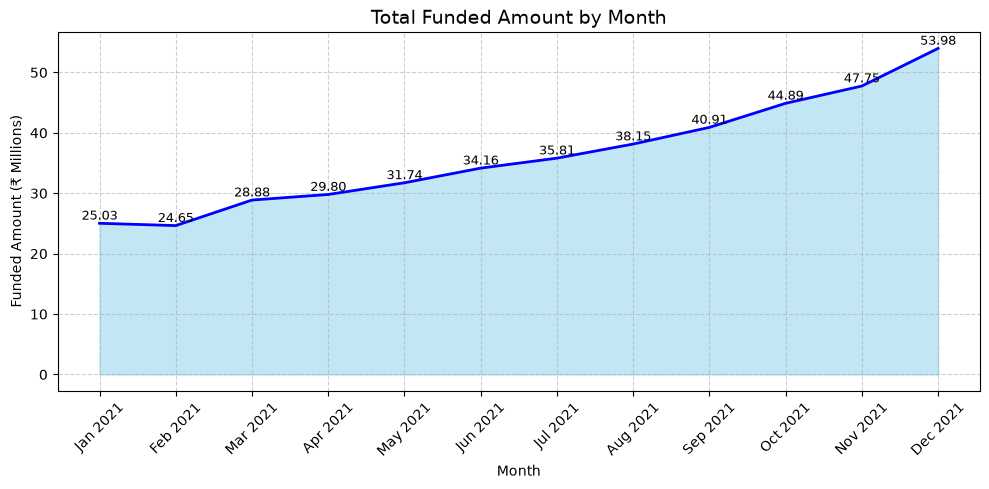

In [35]:

# Ensure 'issue_date' is in datetime format
df['issue_date'] = pd.to_datetime(df['issue_date'])

# Create 'Month Year' label
df['month_name'] = df['issue_date'].dt.strftime('%b %Y')

# Sort the DataFrame by issue_date
df = df.sort_values('issue_date')

# Group by month and get total funded amount
monthly_funded = df.groupby('month_name', sort=False)['loan_amount'].sum().reset_index()

# Convert to millions
monthly_funded['loan_amount_millions'] = monthly_funded['loan_amount'] / 1000000

# Plotting
plt.figure(figsize=(10, 5))
plt.fill_between(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='skyblue', alpha=0.5)
plt.plot(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='blue', linewidth=2)

# Add data labels
for i, row in monthly_funded.iterrows():
    plt.text(row['month_name'], row['loan_amount_millions'] + 0.1, f"{row['loan_amount_millions']:.2f}", 
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

# Chart formatting
plt.title('Total Funded Amount by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Funded Amount (₹ Millions)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


#### Total Received Amount by Month

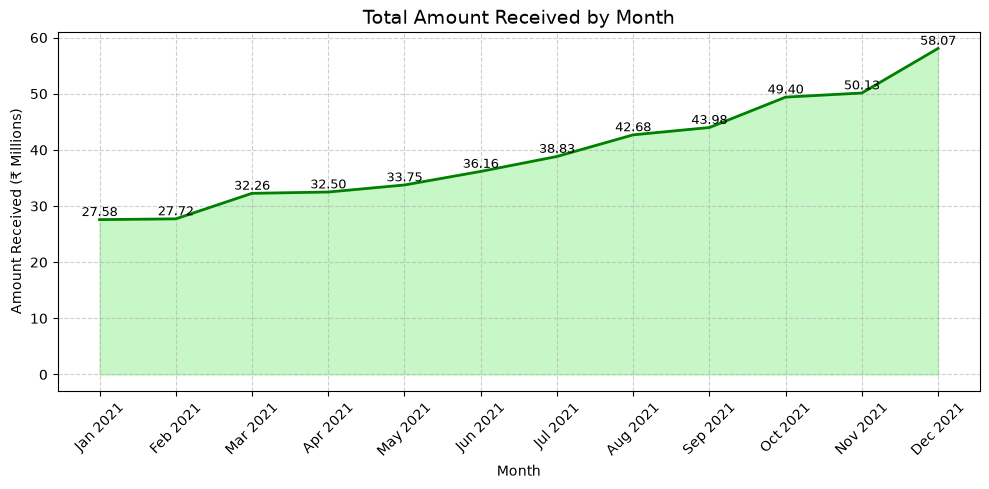

In [36]:
# Make sure 'issue_date' is datetime
df['issue_date'] = pd.to_datetime(df['issue_date'])

# Create 'Month Year' column for grouping
df['month_name'] = df['issue_date'].dt.strftime('%b %Y')

# Sort by date to keep month order intact
df = df.sort_values('issue_date')

# Group by month and calculate total received
monthly_received = df.groupby('month_name', sort=False)['total_payment'].sum().reset_index()

# Convert to ₹ millions
monthly_received['total_payment_millions'] = monthly_received['total_payment'] / 1_000_000

# Plotting the area chart
plt.figure(figsize=(10, 5))
plt.fill_between(monthly_received['month_name'], monthly_received['total_payment_millions'], color='lightgreen', alpha=0.5)
plt.plot(monthly_received['month_name'], monthly_received['total_payment_millions'], color='green', linewidth=2)

# Add data labels
for i, row in monthly_received.iterrows():
    plt.text(row['month_name'], row['total_payment_millions'] + 0.1, f"{row['total_payment_millions']:.2f}", 
             ha='center', va='bottom', fontsize=9, color='black')

# Chart formatting
plt.title('Total Amount Received by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Amount Received (₹ Millions)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### Total Applications by Month

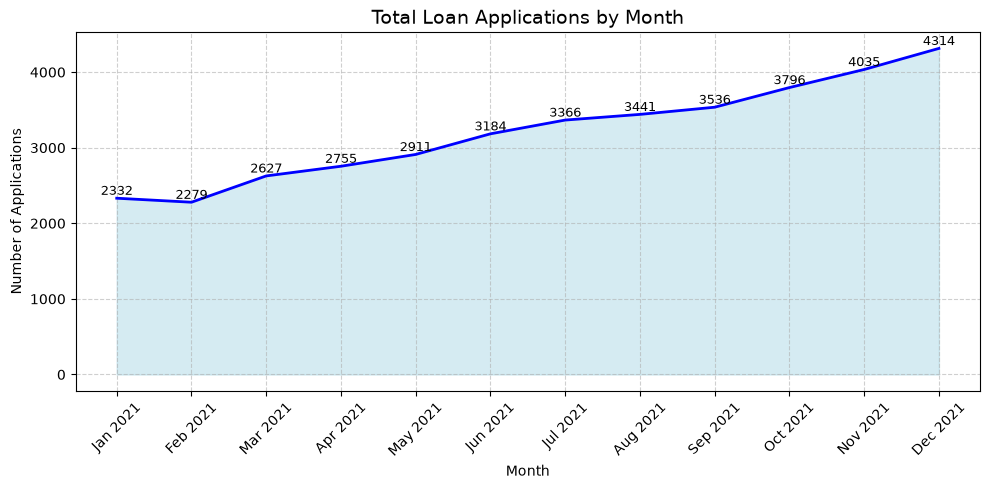

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Make sure 'issue_date' is datetime
df['issue_date'] = pd.to_datetime(df['issue_date'])

# Create 'Month Year' column for grouping
df['month_name'] = df['issue_date'].dt.strftime('%b %Y')

# Sort by issue date to maintain month order
df = df.sort_values('issue_date')

# Group by month and count loan applications
monthly_applications = df.groupby('month_name', sort=False)['id'].count().reset_index()
monthly_applications.rename(columns={'id': 'total_applications'}, inplace=True)

# Plotting the area chart
plt.figure(figsize=(10, 5))
plt.fill_between(monthly_applications['month_name'], monthly_applications['total_applications'], color='lightblue', alpha=0.5)
plt.plot(monthly_applications['month_name'], monthly_applications['total_applications'], color='blue', linewidth=2)

# Add data labels
for i, row in monthly_applications.iterrows():
    plt.text(row['month_name'], row['total_applications'] + 5, f"{row['total_applications']}", 
             ha='center', va='bottom', fontsize=9, color='black')

# Chart formatting
plt.title('Total Loan Applications by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### Total Funded Amount by State

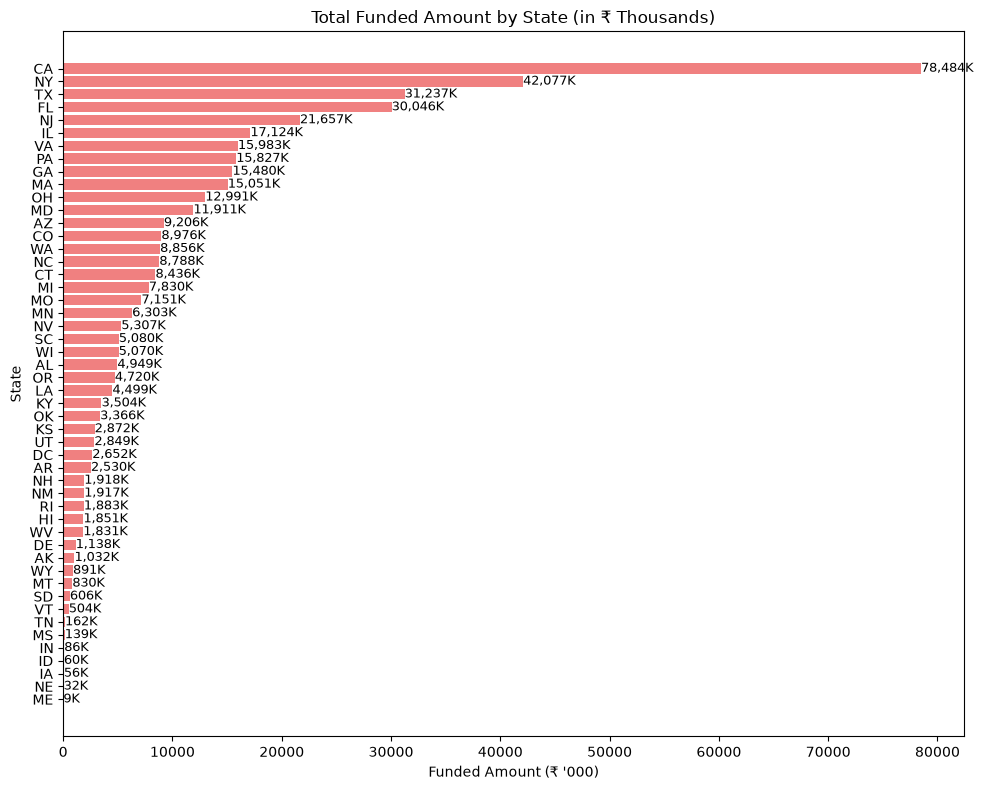

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# Group by state and sum loan amounts (in thousands)
state_funding = df.groupby('address_state')['loan_amount'].sum().sort_values(ascending=True)
state_funding_thousands = state_funding / 1000  # convert to ₹ '000

# Plot horizontal bar chart
plt.figure(figsize=(10, 8))
bars = plt.barh(state_funding_thousands.index, state_funding_thousands.values, color='lightcoral')

# Add data labels with 'K'
for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height() / 2,
             f'{width:,.0f}K', va='center', fontsize=9)

plt.title('Total Funded Amount by State (in ₹ Thousands)')
plt.xlabel('Funded Amount (₹ \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

#### Total Funded Amount by Term

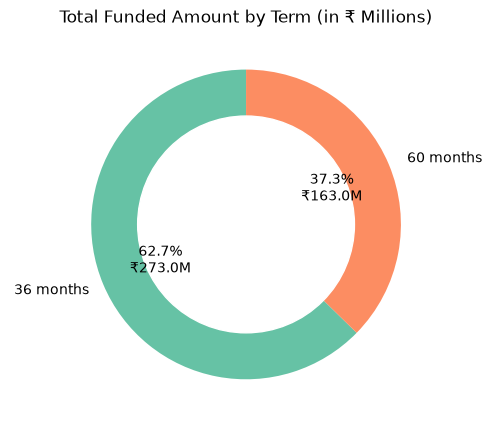

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Group total funded amount by term
term_funding = df.groupby('term')['loan_amount'].sum()

# Convert to ₹ Millions
term_funding_millions = term_funding / 1_000_000

# Function to display both percent and amount
def autopct_format(pct, allvals):
    absolute = int(round(pct/100.*sum(allvals)))
    amount = allvals[absolute == allvals].values[0] if absolute in allvals.values else absolute
    return f"{pct:.1f}%\n₹{amount:.1f}M"

# Plotting the donut chart
plt.figure(figsize=(5, 5))
colors = ['#66c2a5', '#fc8d62']  # Customize if needed

wedges, texts, autotexts = plt.pie(
    term_funding_millions,
    labels=term_funding_millions.index,
    autopct=lambda pct: autopct_format(pct, term_funding_millions),
    startangle=90,
    colors=colors,
    wedgeprops={'width': 0.4}
)

# Draw center circle
plt.gca().add_artist(plt.Circle((0, 0), 0.70, color='white'))

plt.title("Total Funded Amount by Term (in ₹ Millions)")
plt.tight_layout()
plt.show()

#### Total Funded Amount by Employee Length

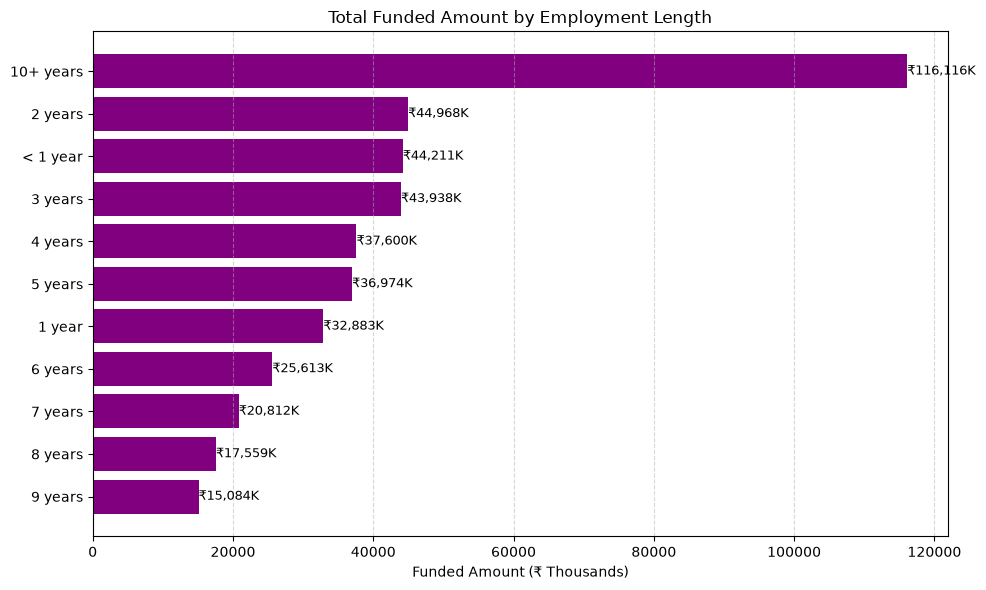

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Group total funded amount by emp_length
emp_funding = df.groupby('emp_length')['loan_amount'].sum().sort_values()

# Convert to ₹ Thousands
emp_funding_thousands = emp_funding / 1_000

# Plotting horizontal bar chart
plt.figure(figsize=(10, 6))
bars = plt.barh(emp_funding_thousands.index, emp_funding_thousands, color='purple')

# Add data labels
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2,
             f"₹{width:,.0f}K", va='center', fontsize=9)

# Chart formatting
plt.xlabel("Funded Amount (₹ Thousands)")
plt.title("Total Funded Amount by Employment Length")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Total Funded Amount by Purpose

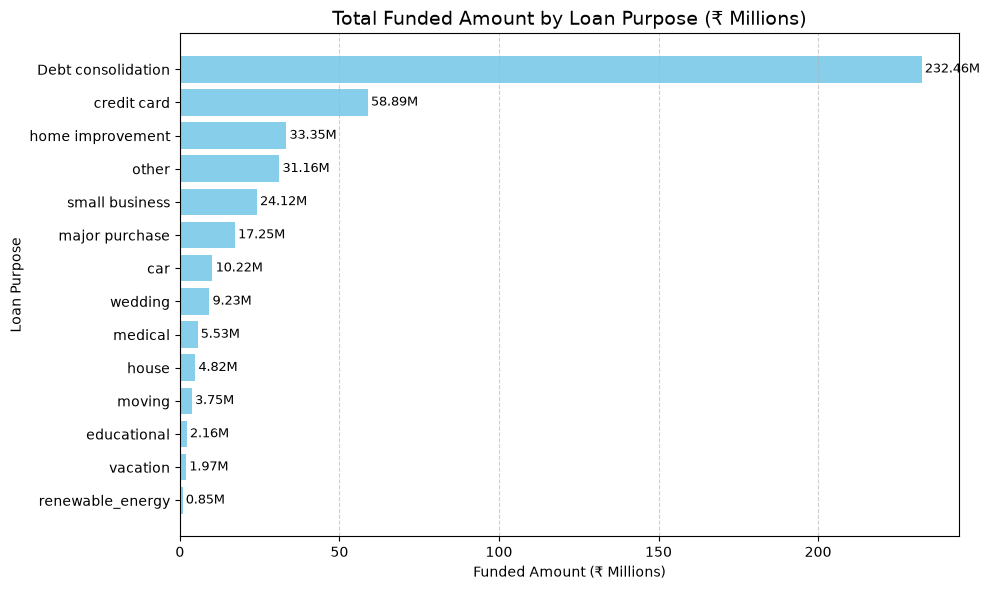

In [41]:
# Group by purpose and calculate total loan amount
purpose_funding = df.groupby('purpose')['loan_amount'].sum().reset_index()
purpose_funding = purpose_funding.sort_values(by='loan_amount', ascending=True)  # Ascending for horizontal bar chart

# Convert to ₹ millions
purpose_funding['loan_amount_millions'] = purpose_funding['loan_amount'] / 1_000_000

# Plot
plt.figure(figsize=(10, 6))
bars = plt.barh(purpose_funding['purpose'], purpose_funding['loan_amount_millions'], color='skyblue')

# Add data labels
for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.2f}M', va='center', fontsize=9)

# Formatting
plt.title('Total Funded Amount by Loan Purpose (₹ Millions)', fontsize=14)
plt.xlabel('Funded Amount (₹ Millions)')
plt.ylabel('Loan Purpose')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### Total Funded Amount by Home Ownership

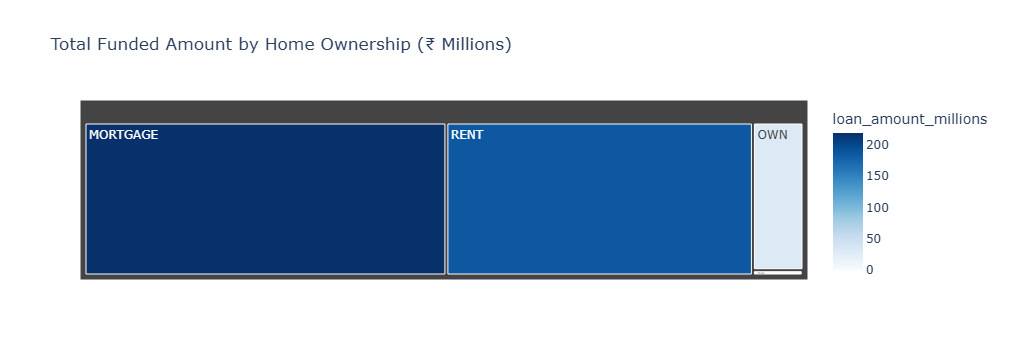

In [42]:
# Group by home_ownership and calculate total funded amount
home_funding = df.groupby('home_ownership')['loan_amount'].sum().reset_index()
home_funding['loan_amount_millions'] = home_funding['loan_amount'] / 1_000_000

# Create Tree Map
fig = px.treemap(
    home_funding,
    path=['home_ownership'],
    values='loan_amount_millions',
    color='loan_amount_millions',
    color_continuous_scale='Blues',
    title='Total Funded Amount by Home Ownership (₹ Millions)'
)

# Show chart
fig.show()


# Connecting python Notebook to MySQl DataBase(bank?_loan_db)

In [43]:
!pip install pymysql sqlalchemy

In [44]:
from sqlalchemy import create_engine
import pandas as pd

# Define your credentials
username = "root"
password = "12345678"
host = "localhost"
port = "3306"
database_name = "bank_loan_db"

# Create the SQLAlchemy engine string
db_connection_str = f"mysql+pymysql://{username}:{password}@{host}:{port}/{database_name}"
engine = create_engine(db_connection_str)

# Test the connection by running a sample query (e.g., fetching table names or reading your table)
query = "SHOW TABLES;"
tables = pd.read_sql(query, con=engine)
print("Connected successfully! Tables in database:")
print(tables)

Connected successfully! Tables in database:
  Tables_in_bank_loan_db
0         bank_loan_data


In [45]:
# Replace 'your_table_name' with the actual table name inside bank_loan_db
df = pd.read_sql("SELECT * FROM bank_loan_data", con=engine)

# Check the first few rows
df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835
